In [ ]:
# import pandas as pd
# import numpy as np

# df = pd.read_csv("/content/sample_data/online_retail.csv", encoding="ISO-8859-1")

# df.head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


In [ ]:
# Check dataset information
df.info()

# Check missing values
df.isnull().sum()

# Check dataset size
df.shape


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype  
---  ------       --------------   -----  
 0   InvoiceNo    541909 non-null  object 
 1   StockCode    541909 non-null  object 
 2   Description  540455 non-null  object 
 3   Quantity     541909 non-null  int64  
 4   InvoiceDate  541909 non-null  object 
 5   UnitPrice    541909 non-null  float64
 6   CustomerID   406829 non-null  float64
 7   Country      541909 non-null  object 
dtypes: float64(2), int64(1), object(5)
memory usage: 33.1+ MB


(541909, 8)

In [ ]:
# Remove rows without CustomerID
df = df.dropna(subset=['CustomerID'])

# Remove cancelled orders (InvoiceNo starting with C)
df = df[~df['InvoiceNo'].astype(str).str.startswith('C')]

# Remove negative/zero quantities and prices
df = df[(df['Quantity'] > 0) & (df['UnitPrice'] > 0)]

# Convert InvoiceDate to datetime
df['InvoiceDate'] = pd.to_datetime(df['InvoiceDate'])

# Check result
df.info()


<class 'pandas.core.frame.DataFrame'>
Index: 397884 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    397884 non-null  object        
 1   StockCode    397884 non-null  object        
 2   Description  397884 non-null  object        
 3   Quantity     397884 non-null  int64         
 4   InvoiceDate  397884 non-null  datetime64[ns]
 5   UnitPrice    397884 non-null  float64       
 6   CustomerID   397884 non-null  float64       
 7   Country      397884 non-null  object        
dtypes: datetime64[ns](1), float64(2), int64(1), object(4)
memory usage: 27.3+ MB


In [ ]:
# Set reference date (latest date in dataset)
reference_date = df['InvoiceDate'].max()

# Create Total Price column
df['TotalPrice'] = df['Quantity'] * df['UnitPrice']

# Create RFM table
rfm = df.groupby('CustomerID').agg({
    'InvoiceDate': lambda x: (reference_date - x.max()).days,
    'InvoiceNo': 'nunique',
    'TotalPrice': 'sum'
})

# Rename columns
rfm.columns = ['Recency', 'Frequency', 'Monetary']

# View RFM data
rfm.head()


,Recency,Frequency,Monetary
CustomerID,,,
12346.0,325,1,77183.60
12347.0,1,7,4310.00
12348.0,74,4,1797.24
12349.0,18,1,1757.55
12350.0,309,1,334.40


In [ ]:
from sklearn.preprocessing import StandardScaler

# Check for skewness
rfm.describe()


,Recency,Frequency,Monetary
count,4338.000000,4338.000000,4338.000000
mean,91.536422,4.272015,2054.266460
std,100.014169,7.697998,8989.230441
min,0.000000,1.000000,3.750000
25%,17.000000,1.000000,307.415000
50%,50.000000,2.000000,674.485000
75%,141.000000,5.000000,1661.740000
max,373.000000,209.000000,280206.020000


In [ ]:
from sklearn.preprocessing import StandardScaler

# Log transform to reduce skewness
rfm_log = np.log1p(rfm)

# Scale the features
scaler = StandardScaler()
rfm_scaled = scaler.fit_transform(rfm_log)

# Convert back to dataframe
rfm_scaled = pd.DataFrame(rfm_scaled,
                          columns=rfm.columns,
                          index=rfm.index)

rfm_scaled.head()


,Recency,Frequency,Monetary
CustomerID,,,
12346.0,1.409894,-0.955214,3.706225
12347.0,-2.146498,1.074425,1.411843
12348.0,0.383971,0.386304,0.716489
12349.0,-0.574674,-0.955214,0.698739
12350.0,1.374758,-0.955214,-0.618962


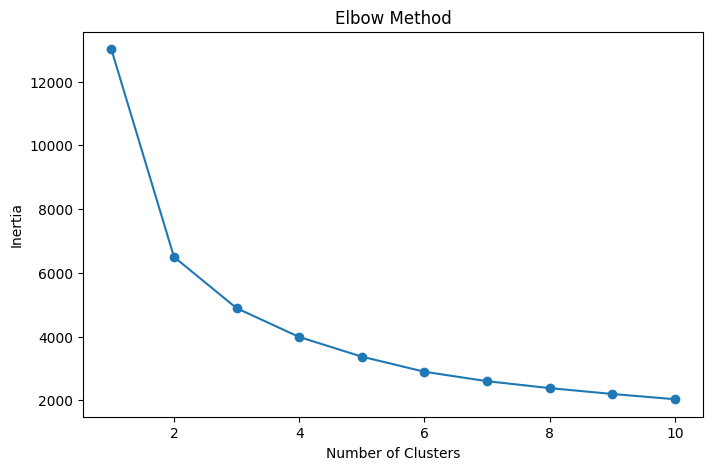

In [ ]:
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans

inertia = []

for k in range(1, 11):
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans.fit(rfm_scaled)
    inertia.append(kmeans.inertia_)

plt.figure(figsize=(8,5))
plt.plot(range(1,11), inertia, marker='o')
plt.xlabel("Number of Clusters")
plt.ylabel("Inertia")
plt.title("Elbow Method")
plt.show()


In [ ]:
from sklearn.cluster import KMeans

# Create K-Means model
kmeans = KMeans(n_clusters=4, random_state=42, n_init=10)

# Fit model and assign clusters
rfm['Cluster'] = kmeans.fit_predict(rfm_scaled)

# View cluster counts
rfm['Cluster'].value_counts()


,count
Cluster,
2,1645
1,1199
0,808
3,686


In [ ]:
# Calculate average values for each cluster
cluster_summary = rfm.groupby('Cluster').mean()

cluster_summary


,Recency,Frequency,Monetary
Cluster,,,
0,17.138614,2.112624,545.188379
1,67.498749,4.225188,1838.547417
2,179.456535,1.320365,350.996493
3,10.349854,13.975219,8293.131356


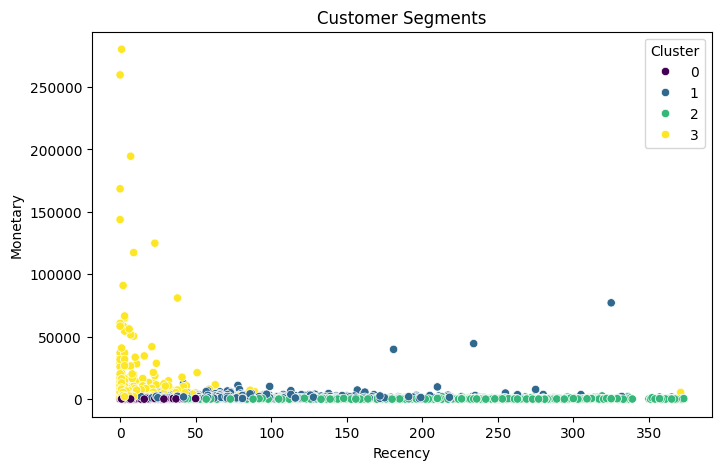

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(8,5))
sns.scatterplot(
    data=rfm,
    x="Recency",
    y="Monetary",
    hue="Cluster",
    palette="viridis"
)

plt.title("Customer Segments")
plt.show()


In [ ]:
from sklearn.metrics import silhouette_score

score = silhouette_score(rfm_scaled, rfm['Cluster'])

print("Silhouette Score:", score)


Silhouette Score: 0.3354623201139756


In [ ]:
# Save clustered customer segments
rfm.to_csv("customer_segments.csv")

print("File saved successfully!")


File saved successfully!


In [ ]:
# Conclusion

# In this project, customer segmentation was performed using the Online Retail dataset containing transaction records from a UK-based online retail store. The main objective was to identify different groups of customers based on their purchasing behavior and provide meaningful business insights.

# The dataset was first cleaned by removing missing customer information, cancelled transactions, and invalid purchase records. After preprocessing, the raw transaction data was transformed into customer-level features using RFM analysis:

# Recency: Measures how recently a customer made a purchase. Customers with lower recency values are considered more active.
# Frequency: Represents the number of purchases made by each customer and shows customer engagement.
# Monetary: Calculates the total amount spent by each customer and identifies high-value customers.

# Since the RFM features had different scales and distributions, log transformation and standardization were applied before clustering. The K-Means clustering algorithm was then used to divide customers into four distinct groups. The Elbow Method was used to determine a suitable number of clusters, and the final model was evaluated using the Silhouette Score.

# The clustering results revealed four meaningful customer segments:

# Cluster 3 - VIP Customers: These customers purchase frequently and contribute the highest revenue. They represent the most valuable customer group and should receive loyalty rewards, personalized offers, and premium services.
# Cluster 1 - Regular Customers: These customers have consistent purchasing behavior and generate moderate revenue. Marketing strategies should focus on maintaining their engagement and encouraging repeat purchases.
# Cluster 0 - New or Occasional Customers: These customers have purchased recently but have lower spending and purchase frequency. They can be targeted with promotional campaigns to increase their involvement.
# Cluster 2 - Inactive Customers: These customers have not purchased recently and show low purchasing activity. Re-engagement strategies such as discounts or reminder campaigns can be used to bring them back.

# The Silhouette Score of approximately 0.335 indicates that the clusters have a reasonable level of separation and that the customer groups identified by the model are meaningful.

# Overall, this project demonstrates how unsupervised machine learning techniques can be used for customer analysis. Customer segmentation helps businesses understand purchasing patterns, improve marketing decisions, increase customer retention, and create personalized strategies for different customer groups.

# I can also help you add a project title, objective, and methodology section to make the notebook look more complete.